# Lab 1: Data Visualization, Data Preprocessing, and Statistical Analysis Using Python

**Student:** Shawn  
**Course:** MSCS 634 — Data Mining  
**Assignment:** Lab 1: Data Visualization, Data Preprocessing, and Statistical Analysis Using Python in Jupyter Notebook

This notebook explores a music-performance dataset, produces visualizations, cleans missing data, checks duplicates, identifies and removes outliers for a focused analysis, reduces data, scales/discretizes numeric fields, and computes descriptive statistics and correlations. Every substantive operation is accompanied by an output or explanation.

**Dataset origin:** `Spotify_Youtube_Sample.csv`, included in the instructor's *Code Examples 3 – Data Statistics* ZIP. It contains track-level observations with artist, album type, YouTube view/engagement counts, and Spotify stream counts. Views, likes, comments, and streams represent counts, not percentages. The values are historical sample observations, **not live numbers**.

**Important limitation:** A track may have multiple versions, and the video and streaming measurements are from different platforms and collection windows. Relationships in this notebook are descriptive associations, not proof that one activity causes another. This is a nonrandom sample and should not be generalized to every song.

## Step 1 — Data collection and inspection

Import Pandas, NumPy, Matplotlib, and the Jupyter display utility. Use a **relative file path** so this notebook works when cloned from GitHub and run from the repository folder. Inspect the dataset's size, columns, and first five rows.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:,.2f}".format)

raw_df = pd.read_csv("Spotify_Youtube_Sample.csv")
print(f"Dataset rows: {len(raw_df):,}; columns: {raw_df.shape[1]}")
print("Columns:", ", ".join(raw_df.columns))
display(raw_df.head())

Dataset rows: 20,718; columns: 10
Columns: Artist, Track, Album, Album_type, Views, Likes, Comments, Licensed, official_video, Stream


,Artist,Track,Album,Album_type,Views,Likes,Comments,Licensed,official_video,Stream
0,Gorillaz,Feel Good Inc.,Demon Days,album,"693,555,221.00","6,220,896.00","169,907.00",True,True,"1,040,234,854.00"
1,Gorillaz,Rhinestone Eyes,Plastic Beach,album,"72,011,645.00","1,079,128.00","31,003.00",True,True,"310,083,733.00"
2,Gorillaz,New Gold (feat. Tame Impala and Bootie Brown),New Gold (feat. Tame Impala and Bootie Brown),single,"8,435,055.00","282,142.00","7,399.00",True,True,"63,063,467.00"
3,Gorillaz,On Melancholy Hill,Plastic Beach,album,"211,754,952.00","1,788,577.00","55,229.00",True,True,"434,663,559.00"
4,Gorillaz,Clint Eastwood,Gorillaz,album,"618,480,958.00","6,197,318.00","155,930.00",True,True,"617,259,738.00"


## Step 2 — Data visualization

Explore the **original data** before making modifications. Missing numerical values are excluded only from the relevant plots via `dropna()`. Four chart types are used to compare groups, examine relationships, understand skew, and reveal differences in data spread. These plots are descriptive and do not imply causation.

### Visualization 1 — Bar chart: tracks by album type

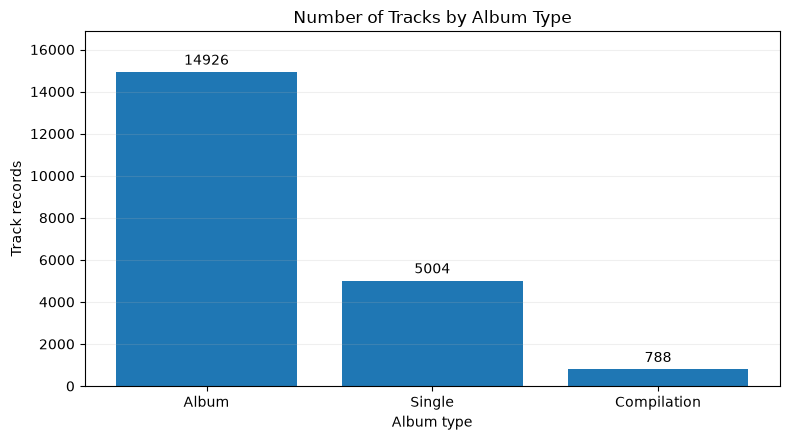

Album type shares (%):


Album_type
album         72.00
single        24.20
compilation    3.80
Name: Percent, dtype: float64

In [2]:
category_counts = raw_df["Album_type"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(category_counts.index.str.title(), category_counts.values)
ax.bar_label(bars, fmt="%d", padding=3)
ax.set_title("Number of Tracks by Album Type")
ax.set_xlabel("Album type")
ax.set_ylabel("Track records")
ax.set_ylim(0, category_counts.max() * 1.13)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()
print("Album type shares (%):")
display((category_counts / len(raw_df) * 100).round(1).rename("Percent"))

**Insight:** Looking at the chart, most of the songs in the dataset come from albums, making up 72% of the total. Singles make up 24.2%, while compilations only account for 3.8%. This shows that albums are much more common in this dataset than the other two categories.


### Visualization 2 — Scatter plot: YouTube views and Spotify streams

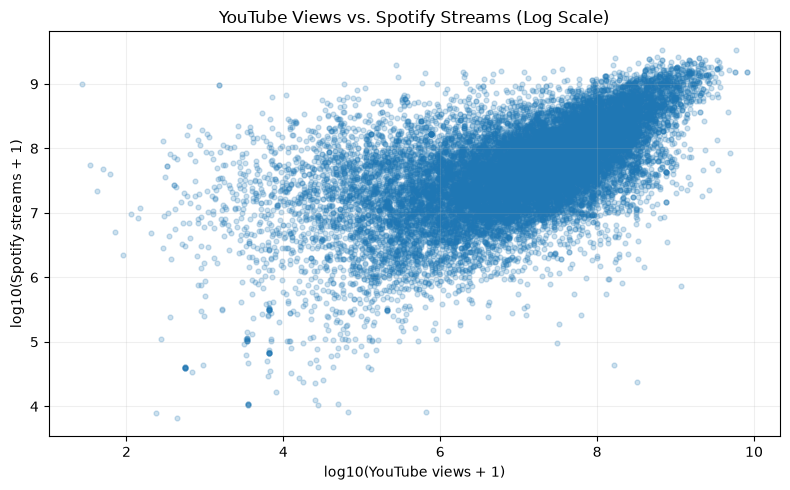

Plotted 19,692 tracks with both measurements available.
Pearson correlation on original count scale: 0.602


In [3]:
pair = raw_df[["Views", "Stream"]].dropna()
# Log10(x+1) makes both very popular and less popular tracks visible.
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(np.log10(pair["Views"] + 1), np.log10(pair["Stream"] + 1),
           alpha=0.22, s=12)
ax.set_title("YouTube Views vs. Spotify Streams (Log Scale)")
ax.set_xlabel("log10(YouTube views + 1)")
ax.set_ylabel("log10(Spotify streams + 1)")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
print(f"Plotted {len(pair):,} tracks with both measurements available.")
print(f"Pearson correlation on original count scale: {pair['Views'].corr(pair['Stream']):.3f}")

**Insight:** This graph shows that songs with more YouTube views usually have more Spotify streams. There are some exceptions, but the overall pattern shows that the numbers tend to increase together. The correlation is 0.602, which means there is a moderate relationship between the two.


### Visualization 3 — Histogram: distribution of YouTube views

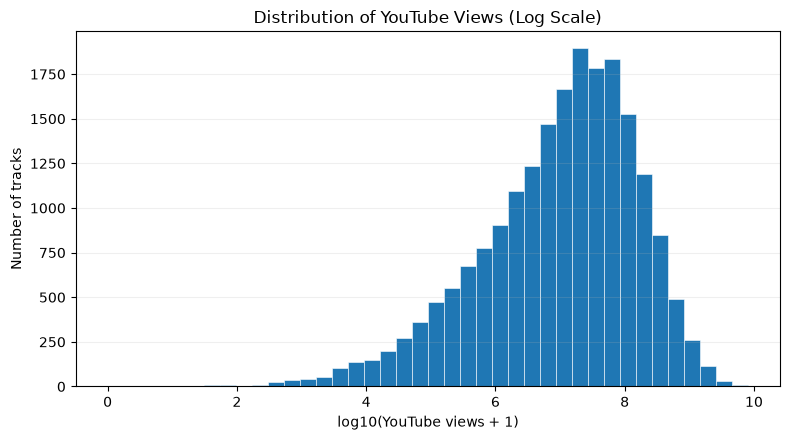

Mean YouTube views: 93,937,821
Median YouTube views: 14,501,095


In [4]:
view_values = raw_df["Views"].dropna()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(np.log10(view_values + 1), bins=40, edgecolor="white", linewidth=0.4)
ax.set_title("Distribution of YouTube Views (Log Scale)")
ax.set_xlabel("log10(YouTube views + 1)")
ax.set_ylabel("Number of tracks")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()
print(f"Mean YouTube views: {view_values.mean():,.0f}")
print(f"Median YouTube views: {view_values.median():,.0f}")

**Insight:** This graph shows how YouTube views are spread across the songs in the dataset. The average number of views is about 93.9 million, but the middle value is only about 14.5 million. This tells us that a few really popular songs have much higher view counts than most of the others, which brings the average up.


### Visualization 4 — Box plot: views across album types

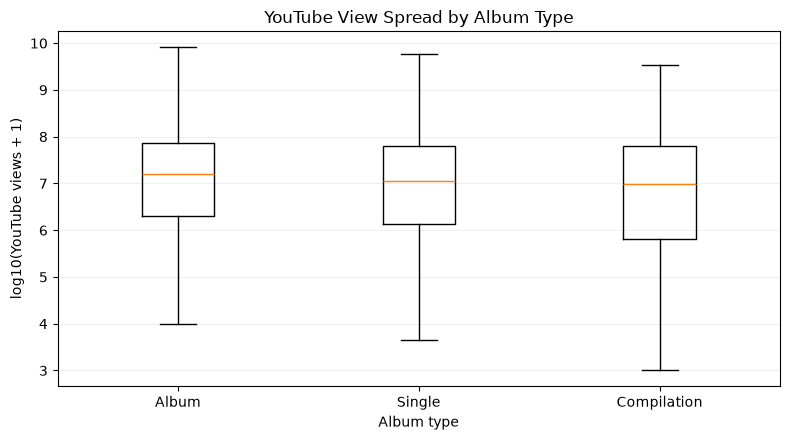

Median YouTube views by album type:


Album_type
album         15,781,710.00
compilation    9,569,629.00
single        11,324,830.00
Name: Median views, dtype: float64

In [5]:
labels = ["album", "single", "compilation"]
by_type = [np.log10(raw_df.loc[raw_df["Album_type"] == kind, "Views"].dropna() + 1)
           for kind in labels]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(by_type, tick_labels=[x.title() for x in labels], showfliers=False)
ax.set_title("YouTube View Spread by Album Type")
ax.set_xlabel("Album type")
ax.set_ylabel("log10(YouTube views + 1)")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()
print("Median YouTube views by album type:")
display(raw_df.groupby("Album_type")["Views"].median().round(0).rename("Median views"))

**Insight:** This graph compares YouTube views between albums, singles, and compilations. Songs from albums have the highest middle value at about 15.8 million views. Singles are next with 11.3 million, followed by compilations with 9.6 million. The chart also shows that views can vary quite a bit in each group. I noticed that songs from albums generally receive more views than the other two categories.


## Step 3 — Data preprocessing

Work on a copy rather than overwriting the original. Each cleaning action is explicitly shown and explained. The analysis applies **median imputation** to numeric counts (resistant to extreme values), **mode imputation** to categorical flags, then a duplicate check, IQR-based trimming of extreme YouTube view counts, sampling, column elimination, Min–Max scaling, and discretization.

**Method caution:** Missing-value imputation and outlier filtering can change the data distribution and statistical relationships. Median replacement is a demonstration technique, not a claim that an unknown count is actually the median. The cleaned dataset should not be interpreted as an unbiased representation of all music tracks.

### 3.1 — Missing value detection and treatment

In [6]:
missing_before = raw_df.isna().sum().rename("Missing before")
print("Missing values by column BEFORE cleaning:")
display(missing_before.to_frame())

# Show rows that contain missing values, so the before/after example is meaningful.
missing_example_indices = raw_df.index[raw_df.isna().any(axis=1)][:5]
columns_to_show = ["Artist", "Track", "Views", "Likes", "Comments", "Stream", "Licensed", "official_video"]
print("Rows with missing values BEFORE:")
display(raw_df.loc[missing_example_indices, columns_to_show])

clean_df = raw_df.copy()
num_cols = ["Views", "Likes", "Comments", "Stream"]
flag_cols = ["Licensed", "official_video"]
for column in num_cols:
    clean_df[column] = clean_df[column].fillna(clean_df[column].median())
for column in flag_cols:
    # The mode is the most frequent observed value; use it for boolean-like flags.
    clean_df[column] = clean_df[column].astype("boolean").fillna(clean_df[column].mode(dropna=True).iloc[0])

print("The SAME rows AFTER imputation:")
display(clean_df.loc[missing_example_indices, columns_to_show])
print("Missing values by column AFTER cleaning:")
display(clean_df.isna().sum().rename("Missing after").to_frame())

Missing values by column BEFORE cleaning:


,Missing before
Artist,0
Track,0
Album,0
Album_type,0
Views,470
Likes,541
Comments,569
Licensed,470
official_video,470
Stream,576


Rows with missing values BEFORE:


,Artist,Track,Views,Likes,Comments,Stream,Licensed,official_video
30,Metallica,Enter Sandman (Remastered),"573,553,706.00","2,828,795.00","81,335.00",NaN,True,True
31,Metallica,Nothing Else Matters (Remastered),"1,209,806,093.00","5,127,599.00","135,946.00",NaN,True,True
32,Metallica,Master of Puppets (Remastered),"20,762,910.00","293,409.00","1,703.00",NaN,True,True
34,Metallica,The Unforgiven (Remastered),"426,125,708.00","1,781,690.00","46,392.00",NaN,False,False
35,Metallica,One (Remastered),524.00,18.00,1.00,NaN,False,False


The SAME rows AFTER imputation:


,Artist,Track,Views,Likes,Comments,Stream,Licensed,official_video
30,Metallica,Enter Sandman (Remastered),"573,553,706.00","2,828,795.00","81,335.00","49,682,981.50",True,True
31,Metallica,Nothing Else Matters (Remastered),"1,209,806,093.00","5,127,599.00","135,946.00","49,682,981.50",True,True
32,Metallica,Master of Puppets (Remastered),"20,762,910.00","293,409.00","1,703.00","49,682,981.50",True,True
34,Metallica,The Unforgiven (Remastered),"426,125,708.00","1,781,690.00","46,392.00","49,682,981.50",False,False
35,Metallica,One (Remastered),524.00,18.00,1.00,"49,682,981.50",False,False


Missing values by column AFTER cleaning:


,Missing after
Artist,0
Track,0
Album,0
Album_type,0
Views,0
Likes,0
Comments,0
Licensed,0
official_video,0
Stream,0


**What I did:** I found that some songs were missing information, such as views, likes, comments, and streams. I filled in the missing numbers using the median value for each column. For the yes-or-no columns, I used the most common answer. After cleaning everything, I checked again and found that there were no missing values left.


### 3.2 — Duplicate detection and removal

In [9]:
print(f"Rows before checking duplicates: {len(clean_df):,}")
print(f"Exact duplicate rows found: {clean_df.duplicated().sum():,}")
clean_df = clean_df.drop_duplicates().copy()
print(f"Rows after dropping duplicates: {len(clean_df):,}")

Rows before checking duplicates: 20,718
Exact duplicate rows found: 0
Rows after dropping duplicates: 20,718


**Decision:** I checked the dataset for duplicate rows and didn't find any. All 20,718 rows were kept because none of them were exact copies. This means I didn't need to remove anything during this step.


### 3.3 — Outlier identification and handling using IQR

In [10]:
# Use only Views to flag high-view observations; trimming many variables at once
# would discard more songs and complicate interpretation.
q1 = clean_df["Views"].quantile(0.25)
q3 = clean_df["Views"].quantile(0.75)
iqr = q3 - q1
lower_bound = max(0, q1 - 1.5 * iqr)  # Counts cannot be negative.
upper_bound = q3 + 1.5 * iqr
mask = (clean_df["Views"] < lower_bound) | (clean_df["Views"] > upper_bound)
outliers = clean_df.loc[mask]

print(f"Q1 = {q1:,.2f}")
print(f"Q3 = {q3:,.2f}")
print(f"IQR = Q3 - Q1 = {iqr:,.2f}")
print(f"Lower bound = {lower_bound:,.2f}")
print(f"Upper bound = {upper_bound:,.2f}")
print(f"Flagged outliers = {len(outliers):,} ({mask.mean():.1%} of cleaned records)")
print("Identified outliers (first five):")
display(outliers[["Artist", "Track", "Views"]].head())

trimmed_df = clean_df.loc[~mask].copy()
print(f"Dataset BEFORE outlier removal: {clean_df.shape}")
print(f"Dataset AFTER outlier removal: {trimmed_df.shape}")
display(trimmed_df[["Artist", "Track", "Views"]].head())

Q1 = 1,950,563.25
Q3 = 67,492,279.50
IQR = Q3 - Q1 = 65,541,716.25
Lower bound = 0.00
Upper bound = 165,804,853.88
Flagged outliers = 2,713 (13.1% of cleaned records)
Identified outliers (first five):


,Artist,Track,Views
0,Gorillaz,Feel Good Inc.,"693,555,221.00"
3,Gorillaz,On Melancholy Hill,"211,754,952.00"
4,Gorillaz,Clint Eastwood,"618,480,958.00"
5,Gorillaz,DARE,"259,021,161.00"
10,Red Hot Chili Peppers,Californication,"1,018,811,259.00"


Dataset BEFORE outlier removal: (20718, 10)
Dataset AFTER outlier removal: (18005, 10)


,Artist,Track,Views
1,Gorillaz,Rhinestone Eyes,"72,011,645.00"
2,Gorillaz,New Gold (feat. Tame Impala and Bootie Brown),"8,435,055.00"
6,Gorillaz,New Gold (feat. Tame Impala and Bootie Brown) ...,"451,996.00"
7,Gorillaz,She's My Collar (feat. Kali Uchis),"1,010,982.00"
8,Gorillaz,Cracker Island (feat. Thundercat),"24,459,820.00"


**Decision:** I used the IQR method to find songs with unusually high or low YouTube views. I found 2,713 outliers, which was about 13.1% of the dataset. After removing these from the cleaned version, I had 18,005 rows left. Some of these songs might just be really popular, so I kept the original data too.


### 3.4 — Data reduction: random sampling and dimension elimination

In [11]:
print("BEFORE data reduction:")
print(f"Shape: {trimmed_df.shape}")
print("Columns:", trimmed_df.columns.tolist())
display(trimmed_df.head(3))

# Reproducible 25% sample; no replacement by default.
sampled_df = trimmed_df.sample(frac=0.25, random_state=42).copy()
# Keep columns relevant for the core comparison and statistics.
columns_to_drop = ["Track", "Album", "Licensed", "official_video"]
reduced_df = sampled_df.drop(columns=columns_to_drop).copy()

print("AFTER sampling 25% and dropping four columns:")
print(f"Shape: {reduced_df.shape}")
print("Columns:", reduced_df.columns.tolist())
display(reduced_df.head(3))

BEFORE data reduction:
Shape: (18005, 10)
Columns: ['Artist', 'Track', 'Album', 'Album_type', 'Views', 'Likes', 'Comments', 'Licensed', 'official_video', 'Stream']


,Artist,Track,Album,Album_type,Views,Likes,Comments,Licensed,official_video,Stream
1,Gorillaz,Rhinestone Eyes,Plastic Beach,album,"72,011,645.00","1,079,128.00","31,003.00",True,True,"310,083,733.00"
2,Gorillaz,New Gold (feat. Tame Impala and Bootie Brown),New Gold (feat. Tame Impala and Bootie Brown),single,"8,435,055.00","282,142.00","7,399.00",True,True,"63,063,467.00"
6,Gorillaz,New Gold (feat. Tame Impala and Bootie Brown) ...,New Gold (feat. Tame Impala and Bootie Brown) ...,single,"451,996.00","11,686.00",241.00,False,True,"10,666,154.00"


AFTER sampling 25% and dropping four columns:
Shape: (4501, 6)
Columns: ['Artist', 'Album_type', 'Views', 'Likes', 'Comments', 'Stream']


,Artist,Album_type,Views,Likes,Comments,Stream
1103,Ice Cube,album,"73,607,374.00","1,129,875.00","37,289.00","54,483,123.00"
2072,Louis Armstrong,album,"3,386,164.00","28,977.00",869.00,"98,732,181.00"
708,Maná,album,"159,021,381.00","357,244.00","9,737.00","122,099,715.00"


**Decision:** I reduced the dataset by randomly selecting 25% of the songs and removing four columns that weren't needed for this part of the assignment. This brought the dataset down from 18,005 rows to 4,501 rows and from 10 columns to 6. Making the dataset smaller helps keep things simple and makes it easier to work with. However, using a smaller sample means some information from the original dataset isn't included.


### 3.5 — Min–Max scaling and view-count discretization

In [12]:
final_df = reduced_df.copy()
print("BEFORE scaling or discretization:")
display(final_df[["Artist", "Album_type", "Views", "Stream"]].head())

for column in num_cols:
    minimum = final_df[column].min()
    maximum = final_df[column].max()
    span = maximum - minimum
    final_df[f"{column}_scaled"] = ((final_df[column] - minimum) / span
                                     if span != 0 else 0.0)

# Data-based tercile bins; quantile labels indicate *relative* view tiers.
final_df["Views_band"] = pd.qcut(final_df["Views"], q=3,
                                 labels=["Low", "Medium", "High"],
                                 duplicates="drop")
print("AFTER scaling and discretization (original counts preserved):")
display(final_df[["Artist", "Views", "Views_scaled", "Stream", "Stream_scaled", "Views_band"]].head())
print("Scaled range check:")
display(final_df[[f"{col}_scaled" for col in num_cols]].agg(["min", "max"]))
print("Count by view tier:")
display(final_df["Views_band"].value_counts(sort=False).rename("Track records"))

# Export the processed subset alongside the original for reproducibility.
final_df.to_csv("Spotify_Youtube_Processed.csv", index=False)
print("Saved: Spotify_Youtube_Processed.csv")

BEFORE scaling or discretization:


,Artist,Album_type,Views,Stream
1103,Ice Cube,album,"73,607,374.00","54,483,123.00"
2072,Louis Armstrong,album,"3,386,164.00","98,732,181.00"
708,Maná,album,"159,021,381.00","122,099,715.00"
17442,Anne-Marie,album,"50,540,295.00","455,322,239.00"
10832,Kany García,album,"1,454,154.00","62,382,717.00"


AFTER scaling and discretization (original counts preserved):


,Artist,Views,Views_scaled,Stream,Stream_scaled,Views_band
1103,Ice Cube,"73,607,374.00",0.44,"54,483,123.00",0.04,High
2072,Louis Armstrong,"3,386,164.00",0.02,"98,732,181.00",0.06,Medium
708,Maná,"159,021,381.00",0.96,"122,099,715.00",0.08,High
17442,Anne-Marie,"50,540,295.00",0.31,"455,322,239.00",0.29,High
10832,Kany García,"1,454,154.00",0.01,"62,382,717.00",0.04,Low


Scaled range check:


,Views_scaled,Likes_scaled,Comments_scaled,Stream_scaled
min,0.00,0.00,0.00,0.00
max,1.00,1.00,1.00,1.00


Count by view tier:


Views_band
Low       1501
Medium    1500
High      1500
Name: Track records, dtype: int64

Saved: Spotify_Youtube_Processed.csv


**Interpretation:** I changed the numerical values to a scale between 0 and 1 to make them easier to compare. I also separated the songs into three groups based on their YouTube views: low, medium, and high. Each group has about 1,500 songs. I kept the original numbers in the dataset so I could still use them for other calculations.


## Step 4 — Statistical analysis

In this section, I looked at the final dataset to better understand the numbers. I used the original views, likes, comments, and streams to calculate different statistics. The dataset has 4,501 songs, and none of the columns have missing information. I also noticed that the average number of YouTube views is much higher than the middle value, which shows that some songs are a lot more popular than others.


### 4.1 — General overview (`info` and `describe`)

In [13]:
print("DATAFRAME INFO:")
final_df.info()
print("\nDESCRIPTIVE STATISTICS (original count variables):")
display(final_df[num_cols].describe().round(2))

DATAFRAME INFO:
<class 'pandas.DataFrame'>
Index: 4501 entries, 1103 to 13751
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   Artist           4501 non-null   str     
 1   Album_type       4501 non-null   str     
 2   Views            4501 non-null   float64 
 3   Likes            4501 non-null   float64 
 4   Comments         4501 non-null   float64 
 5   Stream           4501 non-null   float64 
 6   Views_scaled     4501 non-null   float64 
 7   Likes_scaled     4501 non-null   float64 
 8   Comments_scaled  4501 non-null   float64 
 9   Stream_scaled    4501 non-null   float64 
 10  Views_band       4501 non-null   category
dtypes: category(1), float64(8), str(2)
memory usage: 391.3 KB

DESCRIPTIVE STATISTICS (original count variables):


,Views,Likes,Comments,Stream
count,"4,501.00","4,501.00","4,501.00","4,501.00"
mean,"26,505,467.42","225,540.98","8,082.29","80,401,135.77"
std,"36,838,443.72","371,701.09","37,871.80","125,072,449.65"
min,7.00,0.00,0.00,"23,472.00"
25%,"1,292,138.00","16,474.00",384.00,"14,663,998.00"
50%,"9,905,524.00","91,592.00","2,466.00","40,385,498.00"
75%,"36,310,876.00","273,741.00","7,398.00","90,745,785.00"
max,"165,628,727.00","5,471,656.00","1,714,936.00","1,548,871,694.00"


### 4.2 — Central tendency and extrema

In this section, I calculated the lowest, highest, average, middle, and most common values for views, likes, comments, and streams. I noticed that the averages were higher than the middle values in every category. This tells me that some songs have much higher numbers than others, which brings the averages up.


In [14]:
central_rows = []
for column in num_cols:
    series = final_df[column]
    central_rows.append({
        "Variable": column,
        "Minimum": series.min(),
        "Maximum": series.max(),
        "Mean": series.mean(),
        "Median": series.median(),
        "Mode (first if tied)": series.mode(dropna=True).iloc[0],
    })
central_table = pd.DataFrame(central_rows).set_index("Variable")
print("CENTRAL TENDENCY / EXTREMA:")
display(central_table.round(2))

CENTRAL TENDENCY / EXTREMA:


,Minimum,Maximum,Mean,Median,Mode (first if tied)
Variable,,,,,
Views,7.00,"165,628,727.00","26,505,467.42","9,905,524.00","14,501,095.00"
Likes,0.00,"5,471,656.00","225,540.98","91,592.00","124,481.00"
Comments,0.00,"1,714,936.00","8,082.29","2,466.00","3,277.00"
Stream,"23,472.00","1,548,871,694.00","80,401,135.77","40,385,498.00","49,682,981.50"


### 4.3 — Dispersion

In [15]:
dispersion_rows = []
for column in num_cols:
    series = final_df[column]
    q1_col = series.quantile(0.25)
    q3_col = series.quantile(0.75)
    dispersion_rows.append({
        "Variable": column,
        "Range": series.max() - series.min(),
        "Q1 (25%)": q1_col,
        "Q2 (median)": series.median(),
        "Q3 (75%)": q3_col,
        "IQR": q3_col - q1_col,
        "Variance (sample)": series.var(ddof=1),
        "Std. dev. (sample)": series.std(ddof=1),
    })
dispersion_table = pd.DataFrame(dispersion_rows).set_index("Variable")
print("DISPERSION MEASURES (sample variance and sample SD):")
display(dispersion_table.round(2))

DISPERSION MEASURES (sample variance and sample SD):


,Range,Q1 (25%),Q2 (median),Q3 (75%),IQR,Variance (sample),Std. dev. (sample)
Variable,,,,,,,
Views,"165,628,720.00","1,292,138.00","9,905,524.00","36,310,876.00","35,018,738.00","1,357,070,935,562,705.75","36,838,443.72"
Likes,"5,471,656.00","16,474.00","91,592.00","273,741.00","257,267.00","138,161,696,861.95","371,701.09"
Comments,"1,714,936.00",384.00,"2,466.00","7,398.00","7,014.00","1,434,272,899.09","37,871.80"
Stream,"1,548,848,222.00","14,663,998.00","40,385,498.00","90,745,785.00","76,081,787.00","15,643,117,662,183,636.00","125,072,449.65"


**Insight:** In this section, I looked at how much the numbers vary between songs. I calculated the range, quartiles, IQR, variance, and standard deviation. I noticed that YouTube views and Spotify streams have a pretty large spread. This shows that some songs are much more popular than others, while many songs have much lower numbers.


### 4.4 — Correlation analysis

In [16]:
correlations = final_df[num_cols].corr(method="pearson")
print("PEARSON CORRELATION MATRIX (original count variables):")
display(correlations.round(3))

strongest = correlations.where(~np.eye(len(correlations), dtype=bool)).stack()
strongest_pair = strongest.abs().idxmax()
print(f"Strongest absolute off-diagonal relationship: {strongest_pair[0]} vs "
      f"{strongest_pair[1]} (r = {correlations.loc[strongest_pair]:.3f})")

PEARSON CORRELATION MATRIX (original count variables):


,Views,Likes,Comments,Stream
Views,1.00,0.74,0.29,0.33
Likes,0.74,1.00,0.61,0.33
Comments,0.29,0.61,1.00,0.09
Stream,0.33,0.33,0.09,1.00


Strongest absolute off-diagonal relationship: Views vs Likes (r = 0.738)


**Insight:** I compared YouTube views, likes, comments, and Spotify streams to see how they relate to each other. The strongest relationship was between YouTube views and likes, with a correlation of 0.74. This means songs with more views usually have more likes. I also noticed that YouTube views and Spotify streams had a weaker relationship of 0.33. Overall, some of these numbers are connected, but they don't always increase together.


Conclusions and Reflections

For this lab, I used Python to create graphs from the given dataset of songs from Spotify and YouTube to compare views, likes, comments, and streams. First, I looked at the distribution of album types and found that about 72% of the songs were from albums. Also, as YouTube views increased, so did Spotify streams, though not always by the same margin.
The data set was then cleaned to fill missing values. The median was used to replace missing values. There were 2,713 outliers in the data set, using the IQR method. These were then removed from the dataset used for the analysis. There were 18,005 rows of data left.
I reduced the dataset further to 4,501 rows by deleting some superfluous columns. Next, I scaled the numbers to the range [0, 1] and created 3 categories of songs (low, medium, high) based on their YouTube views.
One interesting point I observed in the data was that there were several instances in which songs had much higher numbers than average. The correlation between YouTube views and likes was 0.74, the strongest among the correlations I compared. The correlation between YouTube views and Spotify streams for the 18,285-row dataset was 0.33 for the same songs.
One of the harder decisions in this lab was how to handle the missing data and outliers. It seemed to me that some of the very high view counts were for extremely popular songs. Thus, viewing a song a million times did not necessarily indicate that something had gone wrong with the data for that song. I therefore kept a copy of the original dataset.
Overall, this lab showed me how to use Python more effectively for organizing data and making graphs,, and also helped me realize the importance of cleaning data before doing any analysis.